# Week 6 Homework: Your Answers vs. Your Vibe-Coded Dashboard

**Week 4 dashboard link:** (https://movielensdashboard-epfatyyrtyrxoqxwd4bis2.streamlit.app/)

---

Two weeks ago you vibe-coded a MovieLens dashboard before you had the tools to judge it. Since then you've had the stats lecture (Week 5) and this week's EDA lecture. Now you do it the real way: answer the same 4 questions yourself, by hand, then audit the dashboard against your own work.

**Ground rules**

- 🚫 **No AI for code or answers in Parts 1 and 2.** Lecture notebooks, pandas/seaborn docs, Google, and Stack Overflow are all fair game. Write Part 3 in your own words too.
- 🔒 **Lock in before you peek.** Finish Parts 1 and 2 (answers written down) *before* you open your dashboard. If you look first, you'll anchor on its numbers and the comparison is worthless.
- 🔢 **Show your numbers.** Every answer needs actual values (counts, averages, titles), not just a vibe.
- ✏️ Written answers go in markdown cells (double-click to edit, Shift+Enter to render). Most are 2 to 4 sentences. Short and specific beats long and vague.

## The data

`movie_ratings.csv` has one row per rating: 100,000 ratings from 943 users on 1,682 movies.

- `user_id`, `movie_id`: who rated, which movie
- `rating`: 1 to 5 stars
- `timestamp`, `rating_year`: when the rating was given
- `age`, `gender`, `occupation`, `zip_code`: the rater
- `title`: movie title, with release year in parentheses
- `year`, `decade`: the movie's release year and decade
- `genres`: all of the movie's genres in one string, separated by the pipe character (a movie can have several)

## Setup

In [3]:
!pip install matplotlib

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------- ----------------- 5.2/9.5 MB 37.3 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 34.0 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 35.9 MB/s  0:00:00

   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   -------------------------- ------------- 4/6 [contourpy]
   --------------------------------- ------ 5/6 [matplotlib]
   --------------------------------- ------ 5/6 [matplotlib]
   -------------------------------


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
!pip install seaborn



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Works whether this notebook sits in the week folder or inside exercise/
data_path = next(p for p in ["data/movie_ratings.csv", "../data/movie_ratings.csv"] if Path(p).exists())
df = pd.read_csv(data_path)
df.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,year,decade,genres,rating_year
0,196,242,3,1997-12-04 15:55:49,49,M,writer,55105,Kolya (1996),1996.0,1990.0,Comedy,1997
1,186,302,3,1998-04-04 19:22:22,39,F,executive,00000,L.A. Confidential (1997),1997.0,1990.0,Crime|Film-Noir|Mystery|Thriller,1998
2,22,377,1,1997-11-07 07:18:36,25,M,writer,40206,Heavyweights (1994),1994.0,1990.0,Children|Comedy,1997
3,244,51,2,1997-11-27 05:02:03,28,M,technician,80525,Legends of the Fall (1994),1994.0,1990.0,Drama|Romance|War|Western,1997
4,166,346,1,1998-02-02 05:33:16,47,M,educator,55113,Jackie Brown (1997),1997.0,1990.0,Crime|Drama,1998


---
# Part 1: Methodology

## 1.1 Know your data first

Before answering anything, check what you're working with: shape, column types, missing values, duplicate rows, and the range of the numeric columns.

In [ ]:
# Your data checks here

print('shape:', df.shape)
missing_years = df.year.isna().sum()
print(f'missing years: ', missing_years )
missing_decades = df.decade.isna().sum()
print(f'missing decade: ', missing_decades )

df.info()

shape: (100000, 13)
missing years:  30
missing decade:  30
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   user_id      100000 non-null  int64  
 1   movie_id     100000 non-null  int64  
 2   rating       100000 non-null  int64  
 3   timestamp    100000 non-null  str    
 4   age          100000 non-null  int64  
 5   gender       100000 non-null  str    
 6   occupation   100000 non-null  str    
 7   zip_code     100000 non-null  str    
 8   title        100000 non-null  str    
 9   year         99970 non-null   float64
 10  decade       99970 non-null   float64
 11  genres       100000 non-null  str    
 12  rating_year  100000 non-null  int64  
dtypes: float64(2), int64(5), str(6)
memory usage: 16.6 MB


**✏️ Data notes:** _(What did you find? Anything missing, duplicated, or surprising? What did you do about it, and why?)_
- year is float, 
- decade is float, 
- timestamp is str, shouldn't it be type Date?
- unknown is a genre, will change to null, since it doesn't give any information about the movie

## 1.2 Decide before you chart

In Week 4 the questions were ambiguous on purpose. This is where *you* commit to an interpretation. Fill it in now, and update it if you change your mind while working (just say so).

**Q1 Genre breakdown**
- What you have to decide: What am I counting, ratings or movies? How do I handle movies that have several genres?
- My choice: i will be counting movies, and for movies with several genres, I will count them in each genre they belong to.
- Why: Counting movies gives better insight into the distribution of genres.

**Q2 Genre satisfaction**
- What you have to decide: "Average rating" of what? How do I treat genres that have very little data?
- My choice: mean of all ratings for that genre and explicitly display number of 
- Why: taking the median gives a better representation of commonest satisfation, since mean can be skewed by outliers

**Q3 Ratings over time**
- What you have to decide: Is every year backed by the same amount of data? What do I do with movies that have no release year?
- My choice: group data by year and calculate the average rating for each year. Drop samples with no release year
- Why: Good view of how ratings have changed over time, and dropping movies with no release year avoids skewing the results

**Q4 Best movies**
- What you have to decide: What is a movie's rating (the mean of what)? Is "at least 50" ≥ or >? What if there's a tie?
- My choice: mean of all ratings for that movie? this will be unfair for movies with very few ratings but high ratings, doesn'r represent the majority is median better? 
- Why: I'll go with median, since we want to cater for the majority of viewers. Median also handles outliers better.

---
# Part 2: Results (by hand, no AI)

Answer each question with a chart or table **and** a written answer with real numbers. Pick the chart type yourself and be ready to defend it in Part 3. Add as many code cells as you need.

## Q1. Genre breakdown

**What's the distribution of genres among the movies that were rated?**

<details>
<summary>Stuck on movies with several genres? Hint</summary>

`genres` is one string like `Crime|Film-Noir|Mystery|Thriller`. To get one row per genre:

```python
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
```

Heads up: after this, a movie with 3 genres takes up 3 rows. Think about what that does to anything you count or average. Exploding is fine for "how often does a genre show up", but be careful calling the result "market share" (the percentages add up to more than 100%).
</details>

In [ ]:
# Q1: your code here
# we need to count the number of movies in each genre, and for movies with multiple genres, 
# we will count them in each genre they belong to.

#display result as table
df_mod = df.copy() #not messing with the original df
df_mod = df_mod.assign(genre=df_mod['genres'].str.split('|')).explode('genre') # splits multi-genre movies new rows per genre
df_mod['genre'] = df_mod['genre'].replace('unknown', pd.NA) #nan better describes missing values

df_mod.sort_values(by='genre', ascending=False, inplace=True)

genre_counts =(df_mod['genre']
               .value_counts()
               .to_frame()
               .rename(columns={'genre':'count'}))
genre_counts['percentage'] = (genre_counts['count'] / genre_counts['count'].sum() * 100)

genre_counts


100.00000000000001


,count,percentage
genre,,
Drama,39895,18.766611
Comedy,29832,14.032975
Action,25589,12.037068
Thriller,21872,10.288590
Romance,19461,9.154456
Adventure,13753,6.469412
Sci-Fi,12730,5.988193
War,9398,4.420820
Crime,8055,3.789073


**✏️ My answer (with numbers):** 
- *Which genres dominate:* Drama represents 18% of movie pool and Comedy represents 14% of pool. 
- *What exactly did you count?:* The number of movies in each genre -> exploded the genres column to count each genre separately. 

## Q2. Genre satisfaction

**Which genres have the highest average rating? Which have the lowest?**

Show how much data is behind each average (for example, the count next to it). An average of 10 ratings and an average of 10,000 ratings are not the same kind of evidence.

Index(['mean', 'count'], dtype='str')


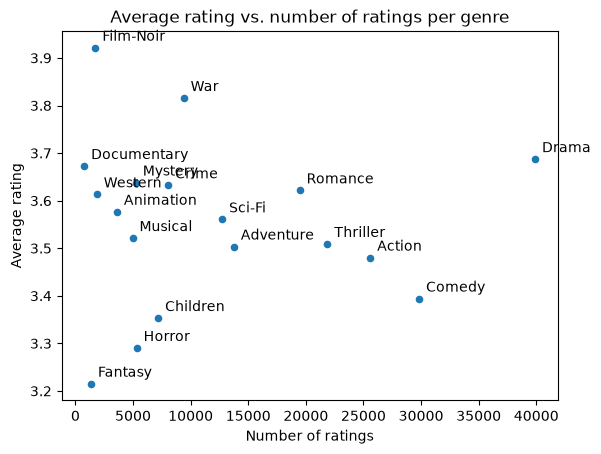

In [169]:
# Q2: your code here
#movies, ratings, genres
gb_genres = df_mod.groupby('genre')['rating'].agg(['mean','count']).sort_values(by='mean', ascending=True)
print(gb_genres.columns)

ax = gb_genres.plot(kind ='scatter', 
                    x ='count', y ='mean',
                    xlabel ='Number of ratings', ylabel='Average rating',
                    title ='Average rating vs. number of ratings per genre')

for genre_name, row in gb_genres.iterrows():
    ax.annotate(genre_name, (row['count'], row['mean']),
                xytext=(5, 5), textcoords='offset points')

**✏️ My answer (with numbers):** 
- *Top and bottom genres* Film-noir highest avg, Fantasy lowest avg 
- *their averages* over 3.9 for Film-noir and 3.2 for Fantasy
- *how much data each one rests on* Film-noir and Fantasy have very little ratings so avg aren't to be trusted 

## Q3. Ratings over time

**How has the mean rating changed across movie release years?**

Show how many ratings each year is based on, alongside the trend.

In [ ]:
# Q3: your code here


**✏️ My answer (with numbers):** _(What's the trend? Is it equally believable across the whole timeline?)_

## Q4. Best movies, with a floor

**What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?**

In [ ]:
# Q4: your code here


**✏️ My answer (with numbers):** _(Both top-5 lists. Which movies dropped out or moved in when the floor went up, and what does that say about small samples?)_

> 🔒 **Stop here.** Parts 1 and 2 should be completely filled in before you open your dashboard.

---
# Part 3: Analysis

Now open your Week 4 dashboard.

## 3.1 How the dashboard got built

Paste 2 prompts that shaped it (from your build log, or from your AI chat history if you didn't keep a log; don't invent any). For each one: what did you ask, what did the AI give you first, and what did you change or accept without checking?

**Prompt 1**
- What I asked:
- AI's first attempt:
- What I changed (or accepted without checking):

**Prompt 2**
- What I asked:
- AI's first attempt:
- What I changed (or accepted without checking):

## 3.2 Compare the answers

Read the answer off your dashboard for each question and put it next to yours.

**Q1**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**Q2**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**Q3**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**Q4**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**When numbers differ, check these first.** Most mismatches come from one of these:

- Counting **ratings** vs. counting **movies**
- One row per rating vs. **one row per rating per genre** (after exploding)
- **Mean of all ratings** vs. the mean of each movie's average
- "At least 50" as ≥ vs. >, or applying the floor before vs. after another step
- What happened to movies with a **missing year**
- Genres with **tiny sample sizes** left in or filtered out

**✏️ Pick two questions and explain what's going on** (2 to 3 sentences each). Track down the *actual cause*: read your dashboard's code, or re-run it with one change. "The AI did it differently" is not an explanation. If the answers match, say why you now trust them.

## 3.3 Chart choices

**Q1**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

**Q2**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

**Q3**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

**Q4**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

Use what you learned about chart choice and misleading charts (Week 5) and this week's lecture. Is it sorted? Are the labels readable? Are the axes honest? Does it show how much data is behind each number?

## 3.4 What can this data actually tell you?

**Answer at least 3 of these 5**, using your own results as evidence.

**1. Who is in this data?** Check the fewest and the most ratings any single user has given (`df.groupby('user_id').size()`), and look at `rating_year`. What kind of person ends up in a dataset like this, and who is missing? How might that tilt your Q2 answer? *(Week 5: sampling bias)*

**2. How sure are you about the bottom genre?** Take the lowest-rated genre from your Q2. How many ratings *and* how many distinct movies is it built on? Estimate a rough 95% interval: mean ± 1.96 × std / √n. Would you bet it's truly the worst genre? *(Week 5: standard error and confidence intervals. Also ask yourself: are 5,000 ratings of the same handful of movies really 5,000 independent pieces of evidence? Remember the one-row-per-model lesson from last week's homework.)*

**3. What can Q3 really say about time?** How many different values does `rating_year` have? So can this data tell you whether people's taste changed over time? What does your Q3 trend actually describe instead? Why might an old movie in this dataset score higher than a recent one? *(Think: who rates a 1940s film in 1997, and which old movies are even in the data?)*

**4. Does "average" depend on how you average?** Recompute Q2 two ways: (a) average over all ratings, (b) average each movie first, then average the movies within each genre. Does the top genre change? "Which genre do *people* like most?" and "which genre has the best *movies*?" are different questions. *(Week 5: confounding, Simpson's paradox)*

**5. Deployment risk.** A studio exec uses your dashboard to decide which genre to green-light. What's the most misleading conclusion they could draw from one of your charts? Write the one-line caveat you'd put under that chart.

**✏️ Your answers:** _(label each one with its number)_

## 3.5 Verdict

**Where I'd override the AI** (something it got wrong, hid, or did poorly, and what your version did better):

**Where the AI held up** (something it did well, or a choice you doubted at first that turned out right):

**One sentence:** looking back at both weeks, who was driving, you or the AI, and when?

---
## Optional stretch

Only if you want more practice:

- Pick 4 genres. How does the mean rating change as viewer age increases? (Try more than 4 and see which genres make the most interesting chart.)
- Plot number of ratings vs. mean rating for each movie. Do the most-rated movies get higher ratings? Is there a correlation? *(Week 5: correlation vs. causation)*

---
## Before you submit

- [ ] Copy this notebook into the `exercise/` folder and rename it `Firstname_Lastname_week_06_exercise.ipynb`
- [ ] **Kernel → Restart & Run All** and make sure it runs top to bottom with your charts showing
- [ ] Every ✏️ cell and every fill-in line is filled in
- [ ] Open a PR from your fork, same as every other week